## TF-IDF baseline for ternary AI-text detection

> This version uses the 256-token truncated dataset (aligned with the Frozen RoBERTa approach) instead of the untruncated one.

In [7]:
!pip -q install huggingface_hub ijson scikit-learn pandas matplotlib
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, accuracy_score)

In [25]:
# connect to a runtime and upload dataset
DATA_PATH = 'ternary_academic_wiki_256.csv'
SEED = 42
VAL_SIZE = 0.15
LABELS = ['human', 'ai_generated', 'ai_refined']

In [ ]:
# load dataset

df = pd.read_csv(DATA_PATH)
display(df.head())

,text,label,pair_id,lang,model,domain,split
0,"Susan Summerall Wiles (born May 14, 1957) is a...",human,36403,english,deepseek-v3,Wiki,train
1,Susan Wiles Susan Summerall Wiles (born May 14...,ai_generated,36403,english,deepseek-v3,Wiki,train
2,"Susan Summerall Wiles (born May 14, 1957) is a...",ai_refined,36403,english,deepseek-v3,Wiki,train
3,"In algebraic geometry, a period is a number th...",human,36404,english,deepseek-v3,Wiki,train
4,Period (Algebraic Geometry) In algebraic geome...,ai_generated,36404,english,deepseek-v3,Wiki,train


In [17]:
# preliminary analysis

print("class distribution:")
print(df["label"].value_counts())
print("\ntrain/test split distribution:")
print(df["split"].value_counts())

class distribution:
label
human           2500
ai_generated    2500
ai_refined      2500
Name: count, dtype: int64

train/test split distribution:
split
train    6000
test     1500
Name: count, dtype: int64


In [27]:
# test splits

train_raw = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

split = GroupShuffleSplit()

train_idx, val_idx = next(split.split(train_raw, groups=train_raw["pair_id"]))
train = train_raw.iloc[train_idx].copy()
validation = train_raw.iloc[val_idx].copy()

print("split sizes:")
print("training:", len(train))
print("validation:", len(validation))
print("testing:", len(test))

split sizes:
training: 4800
validation: 1200
testing: 1500


In [28]:
# train baseline model (tf-idf + log regression)

baseline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression())
])

baseline.fit(train["text"], train["label"])

Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier', LogisticRegression())])

Test accuracy: 0.7947
Test macro-F1: 0.7961

Classification report:
              precision    recall  f1-score   support

       human     0.8110    0.8580    0.8338       500
ai_generated     0.9148    0.7300    0.8120       500
  ai_refined     0.6958    0.7960    0.7425       500

    accuracy                         0.7947      1500
   macro avg     0.8072    0.7947    0.7961      1500
weighted avg     0.8072    0.7947    0.7961      1500



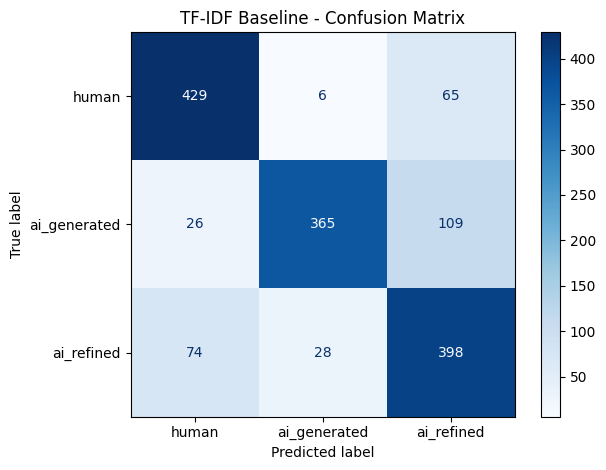


Correct predictions:


,label,prediction,domain,model,pair_id,text
751,ai_generated,ai_generated,Wiki,deepseek-v3,36800,Adam's Testament Overview Adam's Testament is ...
752,ai_refined,ai_refined,Wiki,deepseek-v3,36800,*Adam's Testament* is a 2017 Canadian drama fi...
753,human,human,Wiki,deepseek-v3,36806,Web in Front is a song by American indie rock ...
754,ai_generated,ai_generated,Wiki,deepseek-v3,36806,"""Web in Front"" ""Web in Front"" is an influentia..."
755,ai_refined,ai_refined,Wiki,deepseek-v3,36806,"""Web in Front"" is a track by the American indi..."



Incorrect predictions:


,label,prediction,domain,model,pair_id,text
750,human,ai_refined,Wiki,deepseek-v3,36800,Adam's Testament is a Canadian 2017 drama film...
757,ai_generated,ai_refined,Wiki,deepseek-v3,36811,Colorado in the American Civil War During the ...
760,ai_generated,ai_refined,Wiki,deepseek-v3,36812,LogDog LogDog is a proprietary Intrusion Detec...
763,ai_generated,ai_refined,Wiki,deepseek-v3,36813,Ellen Ratner Early Life and Education Ellen Ra...
765,human,ai_refined,Wiki,deepseek-v3,36815,Queen's Blade: Rebellion is a 2012 anime telev...
766,ai_generated,human,Wiki,deepseek-v3,36815,Queen's Blade: Rebellion Queen's Blade: Rebell...
772,ai_generated,ai_refined,Wiki,deepseek-v3,36821,2016 Tooting by-election The Tooting by-electi...
779,ai_refined,human,Wiki,deepseek-v3,36823,Pilajirao Gaekwad (died 14 May 1732) was a pro...
781,ai_generated,ai_refined,Wiki,deepseek-v3,36824,Douglassia Douglassia is a genus of medium-siz...
784,ai_generated,ai_refined,Wiki,deepseek-v3,36829,"Barbara Jay Barbara Jay (born August 14, 1937)..."



Error counts by true and predicted labels:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,365,109,26
ai_refined,28,398,74
human,6,65,429



Accuracy by domain:


,count,mean
domain,,
Academic,750,0.840000
Wiki,750,0.749333



Accuracy by model:


,count,mean
model,,
deepseek-v3,378,0.793651
gemini-2.5-flash,378,0.833333
gpt-4o,372,0.793011
qwen-max,372,0.758065


In [29]:
# evaluation

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Quantitative evaluation
y_pred = baseline.predict(test["text"])
y_true = test["label"]

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["human", "ai_generated", "ai_refined"],
    digits=4,
    zero_division=0
))

# 2. Confusion matrix
labels = ["human", "ai_generated", "ai_refined"]

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF Baseline - Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Qualitative error analysis
results = test.copy()
results["prediction"] = y_pred
results["correct"] = results["label"] == results["prediction"]

print("\nCorrect predictions:")
display(results[results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(5))

print("\nIncorrect predictions:")
display(results[~results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(10))

# 4. Error distribution
print("\nError counts by true and predicted labels:")
display(pd.crosstab(results["label"], results["prediction"]))

print("\nAccuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))

print("\nAccuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]))